# 👖 Autoencoders

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, datasets, callbacks

2026-11-03 12:41:35.721168: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-03 12:41:36.604856: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-03 12:41:38.466019: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
IMAGE_SIZE = 32
CHANNELS = 1
BATCH_SIZE = 100
BUFFER_SIZE = 1000
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 2
EPOCHS = 20

## 1. Prepare the data <a name="prepare"></a>

In [4]:
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

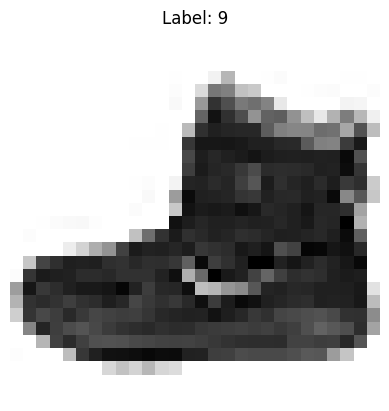

(28, 28)


In [5]:
plt.imshow(x_train[0], cmap="gray_r")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()
print(x_train[0].shape)

In [6]:
# Preprocess the data
def preprocess(imgs):

    imgs = imgs.astype("float32") / 255.0
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=0.0)
    imgs = np.expand_dims(imgs, -1)

    return imgs

In [7]:
x_train = preprocess(x_train)
x_test = preprocess(x_test)

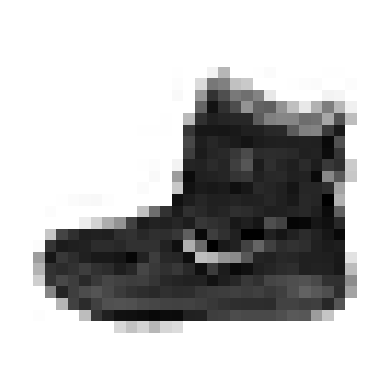

(32, 32, 1)


In [8]:
plt.imshow(x_train[0], cmap="gray_r")
plt.axis("off")
plt.show()
print(x_train[0].shape)

## 2. Build the autoencoder <a name="build"></a>

In [9]:
# Encoder
encoder_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input")
x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(encoder_input)
x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(256, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(512, (3, 3), strides=2, activation="relu", padding="same")(x)
shape = x.shape[1:]

x = layers.Flatten()(x)
encoder_output = layers.Dense(EMBEDDING_DIM, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output)

I0000 00:00:1793688278.672109    6806 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:01:00.0, compute capability: 8.9


In [10]:
# Decoder
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape)))(decoder_input)
x = layers.Reshape(shape)(x)
x = layers.Conv2DTranspose(512, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(256, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(128, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="same")(x)
decoder_output = layers.Conv2D(CHANNELS, (3, 3), strides=1, activation="sigmoid", padding="same", name="decoder_output")(x)

decoder = models.Model(decoder_input, decoder_output)

In [11]:
# Autoencoder
autoencoder = models.Model(encoder_input, decoder(encoder_output))

## 3. Train the autoencoder <a name="train"></a>

In [12]:
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

In [13]:
callback = callbacks.ModelCheckpoint(filepath="autoencoder.keras", save_weights_only=False, save_freq="epoch", monitor="loss", mode="min", save_best_only=True, verbose=1)

In [14]:
autoencoder.fit(x_train, x_train, epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, validation_data=(x_test, x_test), callbacks=callback)

Epoch 1/20


2026-11-03 12:45:33.640986: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f74a80029c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-03 12:45:33.641008: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4060, Compute Capability 8.9
2026-11-03 12:45:33.711037: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-03 12:45:34.351436: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92600


 19/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.6826

I0000 00:00:1793688339.971646    6898 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3630
Epoch 1: loss improved from None to 0.29085, saving model to autoencoder.keras

Epoch 1: finished saving model to autoencoder.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - loss: 0.2908 - val_loss: 0.2551
Epoch 2/20
595/600 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2525
Epoch 2: loss improved from 0.29085 to 0.25057, saving model to autoencoder.keras

Epoch 2: finished saving model to autoencoder.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.2506 - val_loss: 0.2494
Epoch 3/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2477
Epoch 3: loss improved from 0.25057 to 0.24747, saving model to autoencoder.keras

Epoch 3: finished saving model to autoencoder.keras
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.2475 - val_loss: 0.2478
Epoch 4/20
598/600 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2452
Epoch 4: loss improved from 0.24747 to 0.24569, saving model to autoencoder.keras

Epoch 4: finished saving mode

In [15]:
autoencoder.save("autoencoder.keras")
encoder.save("encoder.keras")
decoder.save("decoder.keras")

## 4. Reconstruct using the autoencoder <a name="reconstruct"></a>

In [16]:
n = 10000
example_images = x_test[:n]
example_labels = y_test[:n]

In [17]:
predictions = autoencoder.predict(example_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step


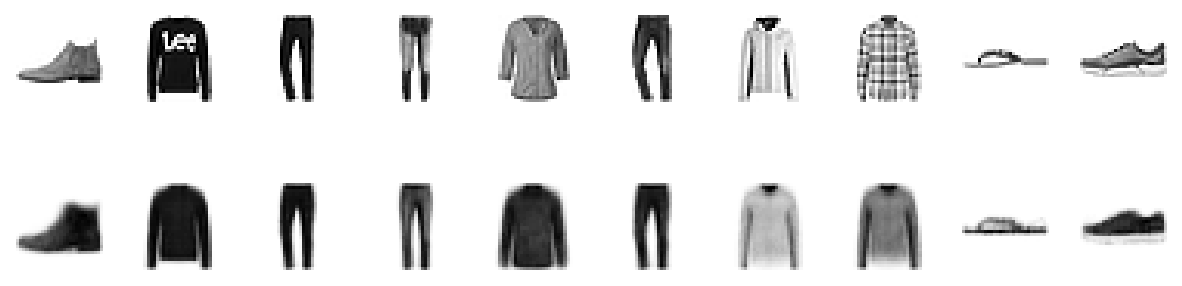

In [18]:
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(example_images[i], cmap="gray_r")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(predictions[i], cmap="gray_r")
    plt.axis("off")

plt.show()

## 5. Embed using the encoder <a name="encode"></a>

In [19]:
embeddings = encoder.predict(example_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [20]:
print(embeddings[:10])

[[-7.1277589e-01 -6.0504198e-01]
 [ 4.8027882e-01  7.6230216e-01]
 [-9.1615391e+00  1.4761384e+01]
 [-4.6800427e+00  5.8283672e+00]
 [ 1.4484479e+00  1.4667188e+00]
 [-5.6011086e+00  9.1290932e+00]
 [-3.9389575e-01  5.9968245e-01]
 [-2.6736278e-03  6.3824534e-01]
 [-7.9838061e+00 -1.0953627e+01]
 [-6.3422523e-02 -4.7154379e+00]]


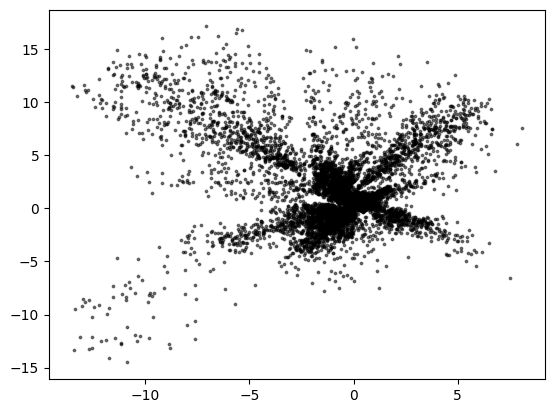

In [21]:
plt.scatter(embeddings[:, 0], embeddings[:, 1], c="black", alpha=0.5, s=3)
plt.show()

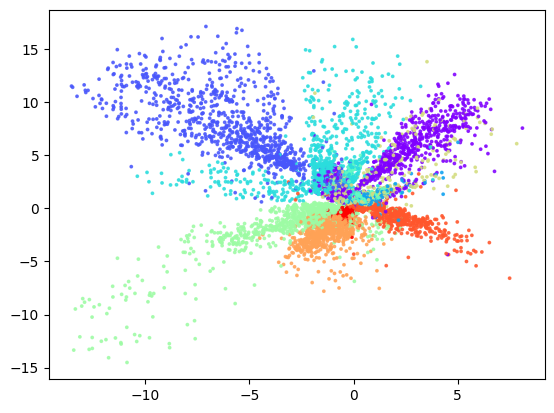

In [23]:
plt.scatter(embeddings[:, 0], embeddings[:, 1], c=y_test[:n], cmap="rainbow", alpha=0.8, s=3)
plt.show()

## 6. Generate using the decoder <a name="decode"></a>

In [24]:
# Get the range of the existing embeddings
mins, maxs = np.min(embeddings, axis=0), np.max(embeddings, axis=0)

# Sample some points in the latent space
grid_width, grid_height = (5, 5)
sample = np.random.uniform(mins, maxs, size=(grid_width * grid_height, EMBEDDING_DIM))

In [25]:
# Decode the sampled points
reconstructions = decoder.predict(sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 986ms/step


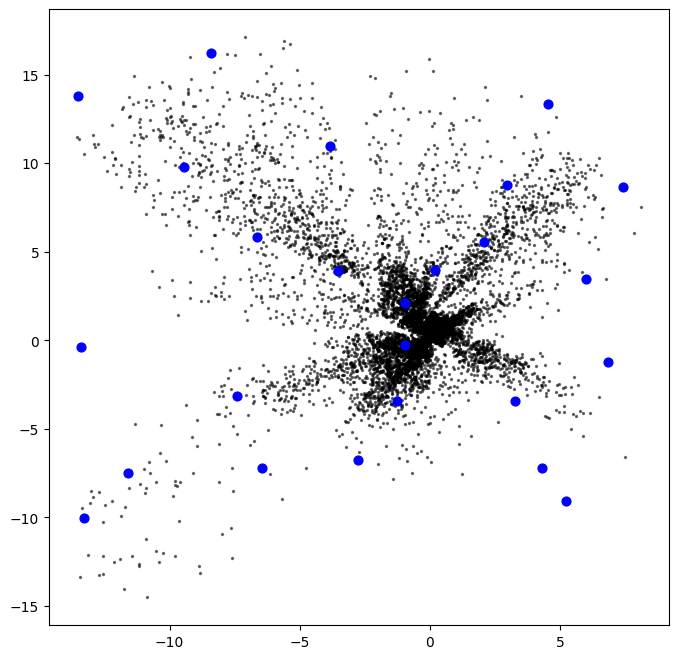

In [26]:
# Plot original and generated latent points
plt.figure(figsize=(8, 8))
plt.scatter(embeddings[:, 0], embeddings[:, 1], c="black", alpha=0.5, s=2)
plt.scatter(sample[:, 0], sample[:, 1], c="blue", s=40)
plt.show()

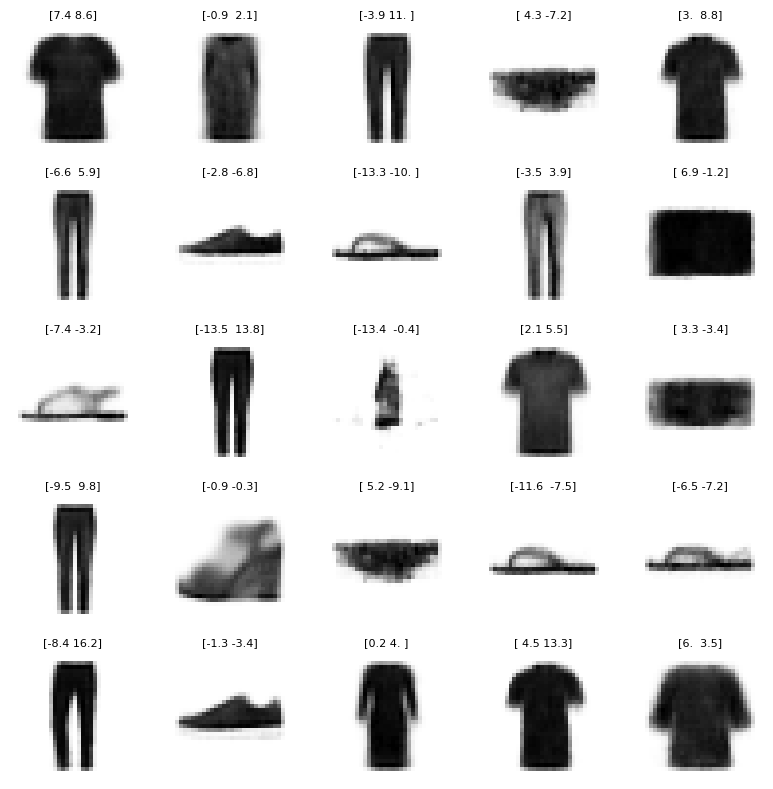

In [27]:
# Display generated images
plt.figure(figsize=(8, 8))

for i in range(grid_width * grid_height):
    plt.subplot(grid_height, grid_width, i + 1)
    plt.imshow(reconstructions[i], cmap="gray_r")
    plt.title(str(np.round(sample[i], 1)), fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

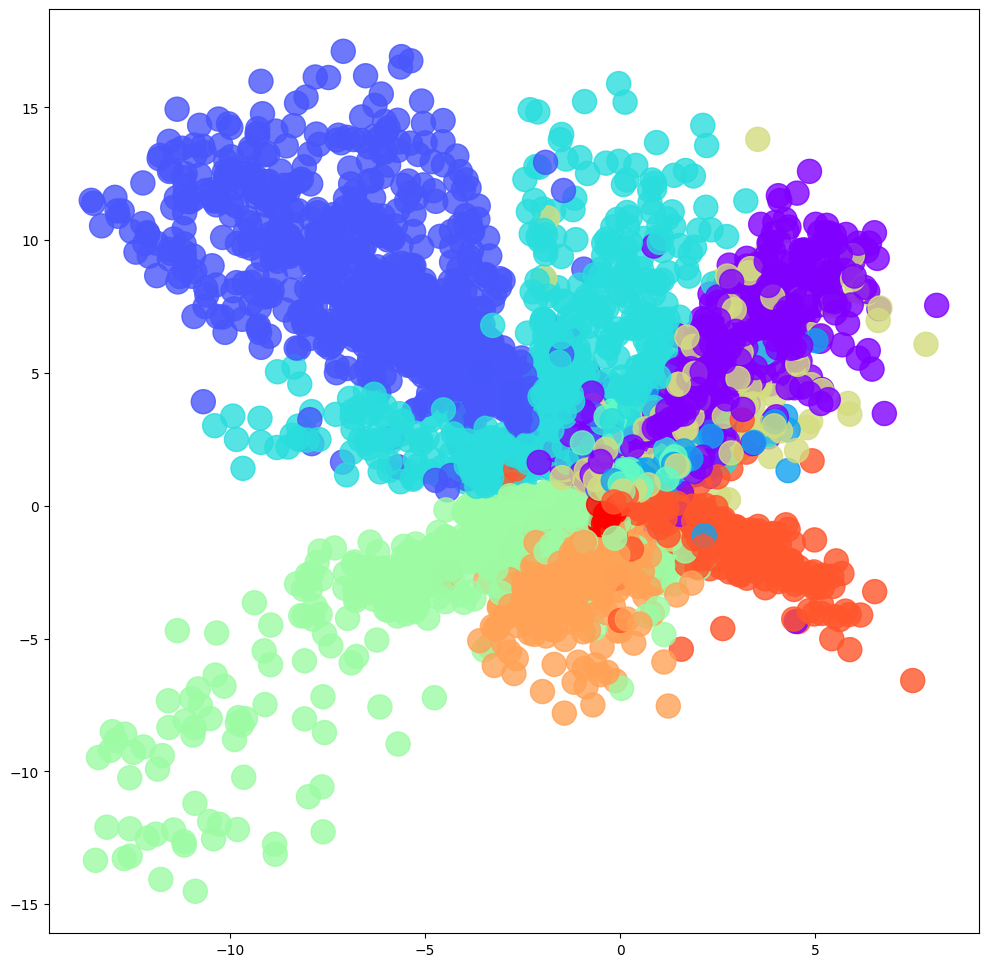

In [29]:
# Plot embeddings by clothing type
plt.figure(figsize=(12, 12))
plt.scatter(embeddings[:, 0], embeddings[:, 1], c=example_labels, cmap="rainbow", alpha=0.8, s=300)
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step


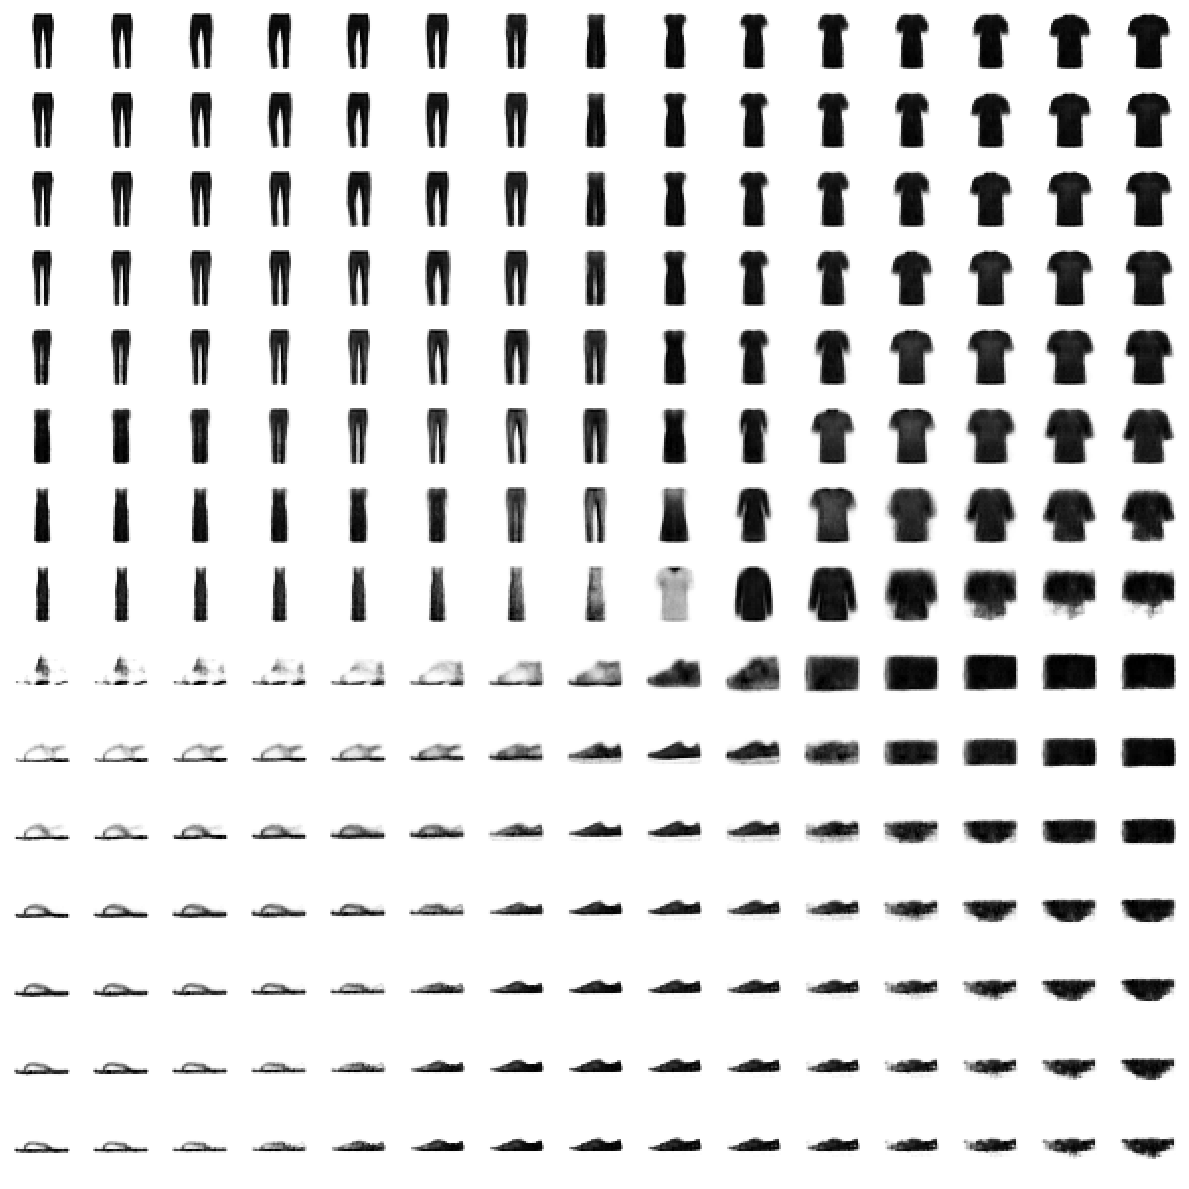

In [30]:
# Generate a grid of latent points
grid_size = 15
x = np.linspace(embeddings[:, 0].min(), embeddings[:, 0].max(), grid_size)
y = np.linspace(embeddings[:, 1].max(), embeddings[:, 1].min(), grid_size)
x, y = np.meshgrid(x, y)
grid = np.column_stack((x.flatten(), y.flatten()))


# Generate images from latent points
reconstructions = decoder.predict(grid)


# Display generated images
plt.figure(figsize=(12, 12))

for i in range(grid_size ** 2):
    plt.subplot(grid_size, grid_size, i + 1)
    plt.imshow(reconstructions[i].squeeze(), cmap="gray_r")
    plt.axis("off")

plt.tight_layout()
plt.show()